ARTI308 - Machine Learning

# Lab 4 Assignment: Data Quality Assessment & Preprocessing
## Dataset: Auto MPG (fuel consumption of cars)

In this assignment we will:

- **Task 1:** identify data quality issues in the dataset.
- **Task 2:** apply one missing value strategy and explain why.
- **Task 3:** detect and handle outliers using IQR.
- **Task 4:** normalize numerical features using both Min-Max and Z-score.
- **Task 5:** apply PCA only if the numerical features show a correlation.

### About the dataset
**Auto MPG** (UCI Machine Learning Repository), 398 cars from the 1970s and early 1980s. Each row is one car model, described by its fuel consumption and technical features. The dataset has real missing values in `horsepower`.

License: CC BY 4.0. Citation: Quinlan, R. (1993). *Auto MPG* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5859H

| Column | Meaning |
|---|---|
| mpg | miles per gallon (fuel efficiency) |
| cylinders | number of engine cylinders |
| displacement | engine size (cubic inches) |
| horsepower | engine power |
| weight | weight of the car (lbs) |
| acceleration | time to accelerate from 0 to 60 mph (seconds) |
| model_year | model year (70 = 1970) |
| origin | 1 = USA, 2 = Europe, 3 = Japan |
| car_name | car brand and model |

## 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")
pd.set_option("display.max_columns", None)

## 2. Load the dataset
The file `auto-mpg.data` has no header, the values are separated by spaces, and missing values are written as `?`. So we must give the column names ourselves and tell pandas that `?` means missing.

In [2]:
DATA_PATH = "data/auto-mpg.data"

cols = ["mpg", "cylinders", "displacement", "horsepower", "weight",
        "acceleration", "model_year", "origin", "car_name"]

df = pd.read_csv(DATA_PATH, sep=r"\s+", names=cols, na_values="?", quotechar='"')
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino


**Observation:** The data loaded correctly after we gave the column names and told pandas that `?` means missing. Each row is one car, with numbers such as `mpg`, `horsepower` and `weight`, and a text column `car_name`.

In [3]:
print("Shape (rows, columns):", df.shape)
df.describe(include="all")

Shape (rows, columns): (398, 9)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
count,398.000000,398.000000,398.000000,392.000000,398.000000,398.000000,398.000000,398.000000,398
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,305
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ford pinto
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6
mean,23.514573,5.454774,193.425879,104.469388,2970.424623,15.568090,76.010050,1.572864,NaN
std,7.815984,1.701004,104.269838,38.491160,846.841774,2.757689,3.697627,0.802055,NaN
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000,1.000000,NaN
25%,17.500000,4.000000,104.250000,75.000000,2223.750000,13.825000,73.000000,1.000000,NaN
50%,23.000000,4.000000,148.500000,93.500000,2803.500000,15.500000,76.000000,1.000000,NaN
75%,29.000000,8.000000,262.000000,126.000000,3608.000000,17.175000,79.000000,2.000000,NaN


**Observation:** The dataset has 398 rows and 9 columns. `horsepower` has only 392 values while the other numeric columns have 398, so it has missing values. The columns are on very different scales (`weight` is in the thousands, `acceleration` is around 15).

---
# Task 1: Identify data quality issues
Check the three kinds of problems: **incomplete** (missing values), **noisy** (outliers or errors), and **inconsistent** (wrong types, formats or spelling).

### 1.1 Data types
Data types must match the real meaning of each column. Ask yourself: is `origin` really a number, or a category?

In [4]:
df.dtypes

mpg             float64
cylinders         int64
displacement    float64
horsepower      float64
weight          float64
acceleration    float64
model_year        int64
origin            int64
car_name            str
dtype: object

**Observation:** Most columns have the correct type: numbers are `int64` or `float64` and `car_name` is text. But `origin` is stored as a number (1, 2, 3) while it really means a category (the country of origin), and `cylinders` also behaves like a category. `horsepower` is `float64` because it contains missing values.

### 1.2 Missing values

In [5]:
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
})
missing[missing["missing_count"] > 0]

,missing_count,missing_percent
horsepower,6,1.51


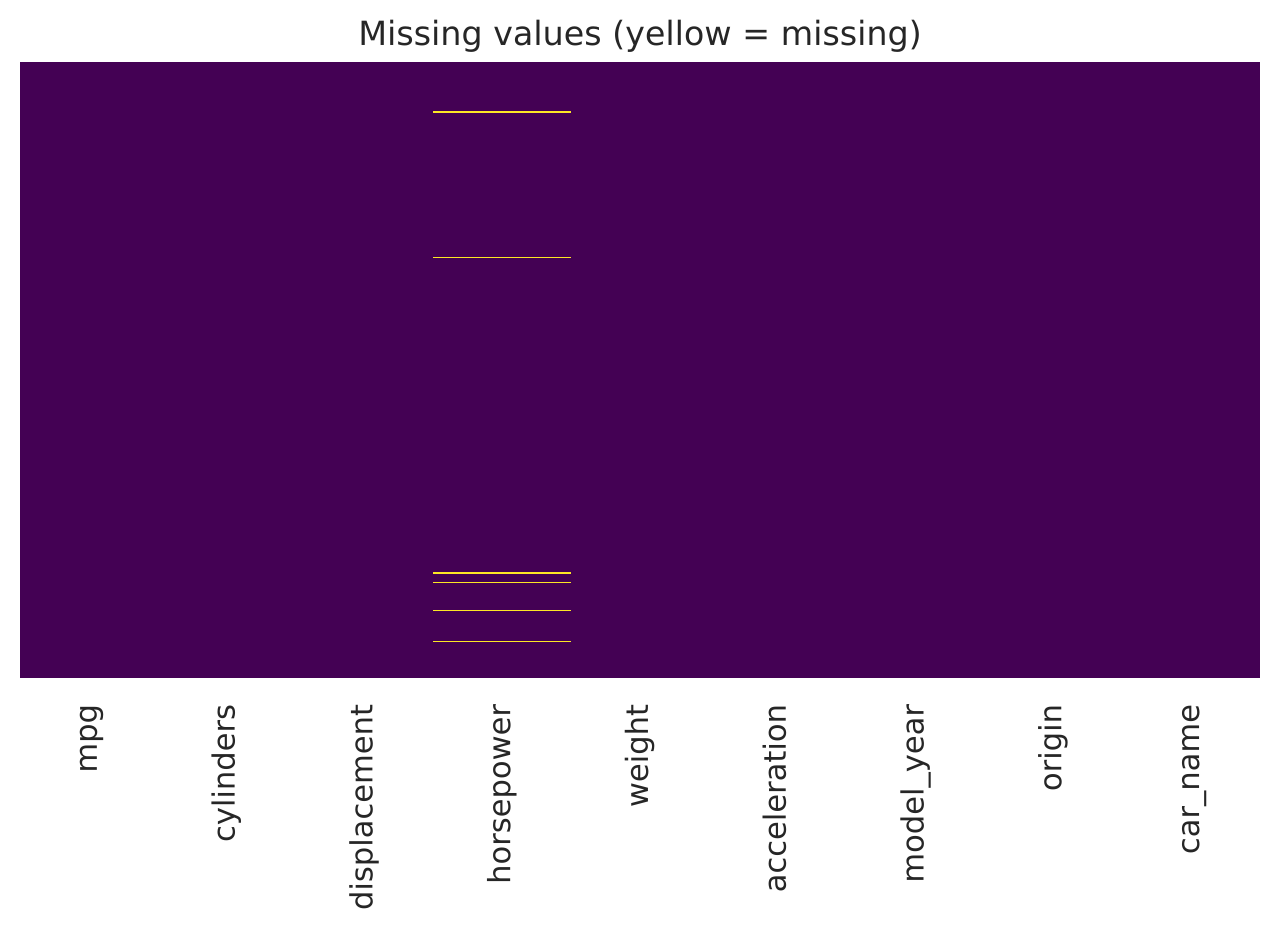

In [6]:
plt.figure(figsize=(8, 4))
sns.heatmap(df.isna(), yticklabels=False, cbar=False, cmap="viridis")
plt.title("Missing values (yellow = missing)")
plt.show()

**Observation:** Only `horsepower` has missing values: 6 rows, which is 1.51% of the data. The heatmap shows a few yellow lines only in the `horsepower` column and none in the other columns.

### 1.3 Duplicate rows

In [7]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


**Observation:** There are 0 duplicate rows, so no rows need to be dropped.

### 1.4 Inconsistent text
The `car_name` column starts with the brand name. If the same brand is written in different ways, it will be counted as different brands. Look carefully at the list below.

In [8]:
brand = df["car_name"].str.split().str[0]
brand.value_counts().sort_index()

car_name
amc              28
audi              7
bmw               2
buick            17
cadillac          2
capri             1
chevroelt         1
chevrolet        43
chevy             3
chrysler          6
datsun           23
dodge            28
fiat              8
ford             51
hi                1
honda            13
maxda             2
mazda            10
mercedes          1
mercedes-benz     2
mercury          11
nissan            1
oldsmobile       10
opel              4
peugeot           8
plymouth         31
pontiac          16
renault           5
saab              4
subaru            4
toyota           25
toyouta           1
triumph           1
vokswagen         1
volkswagen       15
volvo             6
vw                6
Name: count, dtype: int64

**Observation:** The same brand is written in different ways: `chevrolet`, `chevroelt` and `chevy`; `toyota` and `toyouta`; `volkswagen`, `vw` and `vokswagen`; `mazda` and `maxda`; `mercedes` and `mercedes-benz`. If we count brands, these would be counted as different brands, so they must be cleaned before using `car_name`.

### Summary of data quality issues
1. **Incomplete:** `horsepower` has 6 missing values (1.51%), written as `?` in the file.
2. **Inconsistent:** brand names in `car_name` have spelling mistakes and different names for the same brand (for example `chevroelt`, `chevy`, `toyouta`, `vw`, `maxda`).
3. **Wrong type meaning:** `origin` is stored as a number but it is a category.
4. **Possible outliers:** `horsepower`, `acceleration` and `mpg` have values outside the IQR limits (checked in Task 3). No duplicate rows were found.

---
# Task 2: Handle missing values (one strategy)
We compare three strategies on the column with missing values, then choose **one** and explain why.

### Strategy 1: Remove records
Works well if only a small number of rows have missing values.

In [9]:
df_remove = df.dropna()
print("With NaN:   ", df.shape)
print("Without NaN:", df_remove.shape)
print("Rows lost:  ", round((1 - len(df_remove) / len(df)) * 100, 2), "%")

With NaN:    (398, 9)
Without NaN: (392, 9)
Rows lost:   1.51 %


### Strategy 2: Mean imputation

In [10]:
df_mean = df.copy()
df_mean["horsepower"] = df_mean["horsepower"].fillna(df_mean["horsepower"].mean())
print("Mean used:", round(df["horsepower"].mean(), 2))
df_mean["horsepower"].describe().round(2)

Mean used: 104.47


count    398.00
mean     104.47
std       38.20
min       46.00
25%       76.00
50%       95.00
75%      125.00
max      230.00
Name: horsepower, dtype: float64

### Strategy 3: Median imputation

In [11]:
df_median = df.copy()
df_median["horsepower"] = df_median["horsepower"].fillna(df_median["horsepower"].median())
print("Median used:", df["horsepower"].median())
df_median["horsepower"].describe().round(2)

Median used: 93.5


count    398.00
mean     104.30
std       38.22
min       46.00
25%       76.00
50%       93.50
75%      125.00
max      230.00
Name: horsepower, dtype: float64

Compare how each strategy changes the mean and the spread of `horsepower`:

In [12]:
comparison = pd.DataFrame({
    "original (NaN ignored)": df["horsepower"].agg(["count", "mean", "median", "std"]),
    "after removing rows":    df_remove["horsepower"].agg(["count", "mean", "median", "std"]),
    "after mean imputation":  df_mean["horsepower"].agg(["count", "mean", "median", "std"]),
    "after median imputation": df_median["horsepower"].agg(["count", "mean", "median", "std"]),
}).round(2)
comparison

,original (NaN ignored),after removing rows,after mean imputation,after median imputation
count,392.00,392.00,398.00,398.00
mean,104.47,104.47,104.47,104.30
median,93.50,93.50,95.00,93.50
std,38.49,38.49,38.20,38.22


**Observation:** All three strategies keep the mean of `horsepower` close to 104.5 (the original mean is 104.47). Median imputation gives a mean of 104.30 and keeps the median at 93.5, while mean imputation moves the median to 95. Removing rows keeps the statistics the same but loses 6 rows.

### My chosen strategy
**Median imputation.** Only 6 rows (1.51%) are missing, so removing them would also be acceptable, but imputation keeps all 398 rows. The median is better than the mean here because `horsepower` is skewed to the right (mean 104.5 is higher than median 93.5) and has outliers, so the median is not pulled by extreme values.

The code below applies the strategy to a new dataframe called `df_clean`.

In [13]:
df_clean = df.copy()
df_clean["horsepower"] = df_clean["horsepower"].fillna(df_clean["horsepower"].median())

print("Missing values after handling:")
print(df_clean.isna().sum())

Missing values after handling:
mpg             0
cylinders       0
displacement    0
horsepower      0
weight          0
acceleration    0
model_year      0
origin          0
car_name        0
dtype: int64


**Observation:** After median imputation every column has 0 missing values, so `df_clean` is complete and keeps all 398 rows.

---
# Task 3: Detect and handle outliers using IQR
Outliers are extreme values that can distort models. The IQR method marks as outliers the values outside:

`Q1 - 1.5 x IQR`  and  `Q3 + 1.5 x IQR`, where `IQR = Q3 - Q1`.

We use the numerical columns that measure something (not `cylinders`, `model_year` or `origin`).

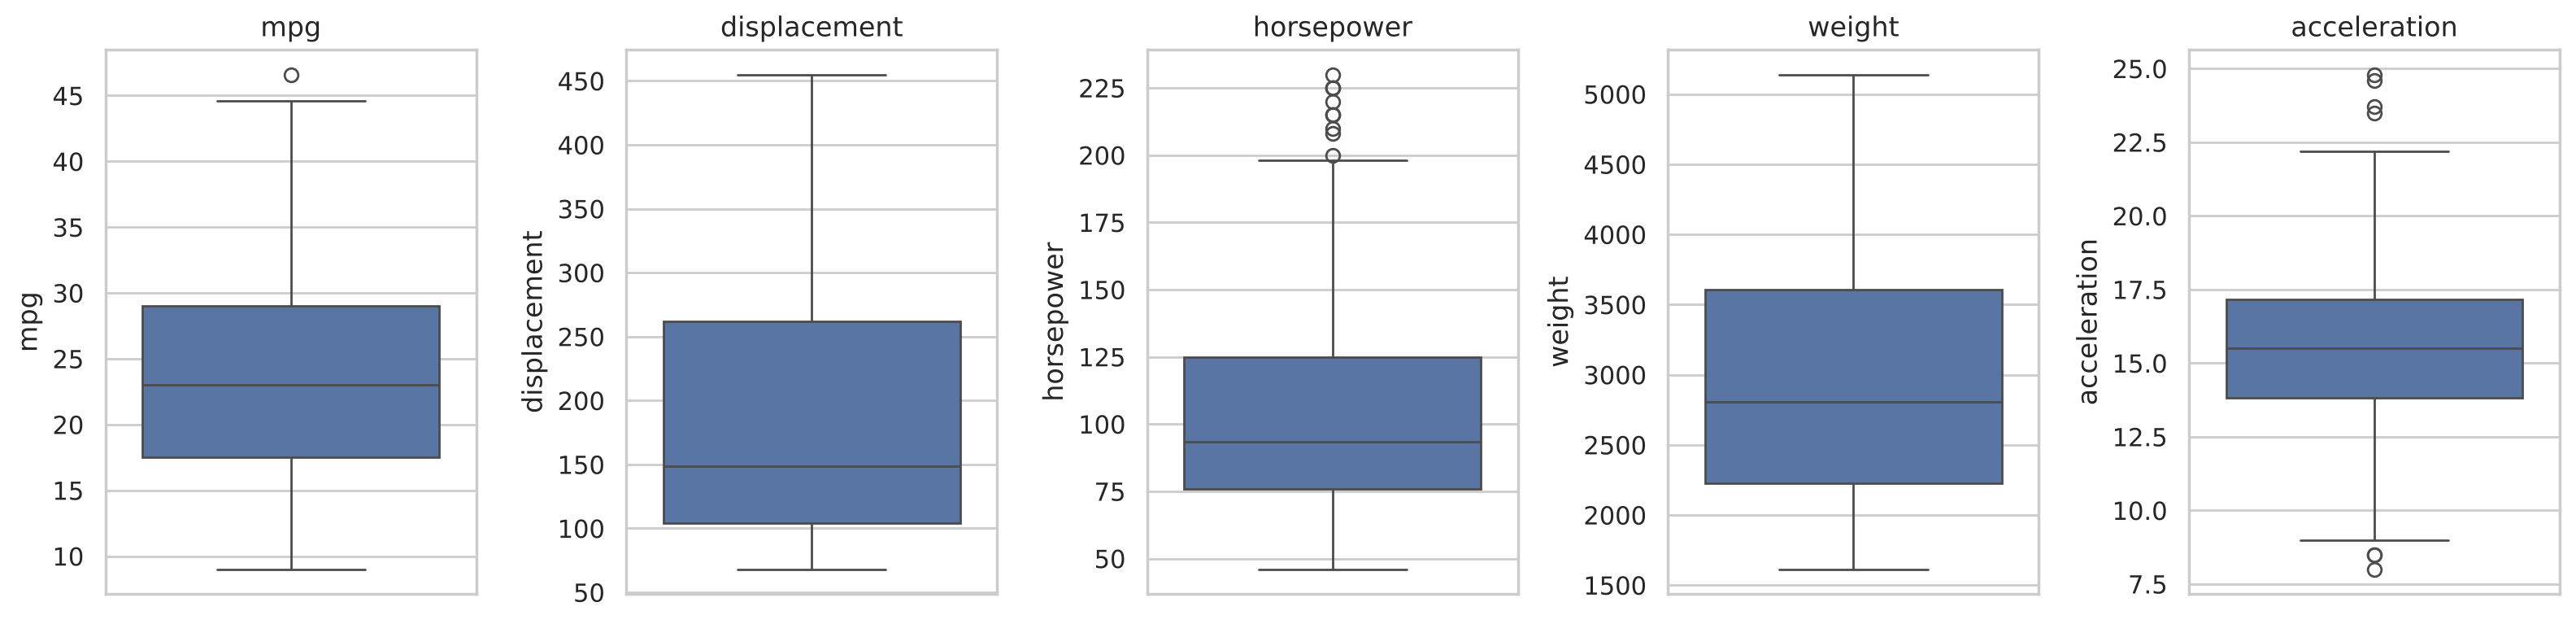

In [14]:
num_cols = ["mpg", "displacement", "horsepower", "weight", "acceleration"]

plt.figure(figsize=(16, 4))
for i, col in enumerate(num_cols, 1):
    plt.subplot(1, 5, i)
    sns.boxplot(y=df_clean[col])
    plt.title(col)
plt.tight_layout()
plt.show()

**Observation:** The boxplots show dots outside the whiskers for `horsepower` and `acceleration`, and one dot for `mpg`. `displacement` and `weight` show no dots.

In [15]:
def iqr_bounds(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

rows = []
for col in num_cols:
    lower, upper = iqr_bounds(df_clean[col])
    n_out = ((df_clean[col] < lower) | (df_clean[col] > upper)).sum()
    rows.append({"feature": col, "lower": round(lower, 2), "upper": round(upper, 2), "n_outliers": n_out})

outlier_table = pd.DataFrame(rows)
outlier_table

,feature,lower,upper,n_outliers
0,mpg,0.25,46.25,1
1,displacement,-132.38,498.62,0
2,horsepower,2.50,198.50,11
3,weight,147.38,5684.38,0
4,acceleration,8.80,22.20,7


**Observation:** The IQR method finds 11 outliers in `horsepower` (above 198.5), 7 in `acceleration` (3 below 8.8 and 4 above 22.2), and 1 in `mpg` (above 46.25). `displacement` and `weight` have 0 outliers.

### Handling the outliers
Not every outlier is an error. A powerful sports car may have a very high `horsepower` and still be a valid car. Before removing outliers ask: *is it a data entry mistake, or a valid but rare observation?*

We apply the two options so you can compare them:

**Option A: Remove the outliers** (here for `horsepower`)

In [16]:
lower, upper = iqr_bounds(df_clean["horsepower"])
df_no_outliers = df_clean[(df_clean["horsepower"] >= lower) & (df_clean["horsepower"] <= upper)]

print("With outliers:   ", df_clean.shape)
print("Without outliers:", df_no_outliers.shape)

With outliers:    (398, 9)
Without outliers: (387, 9)


**Option B: Cap the outliers** (replace extreme values by the IQR limits, so no rows are lost)

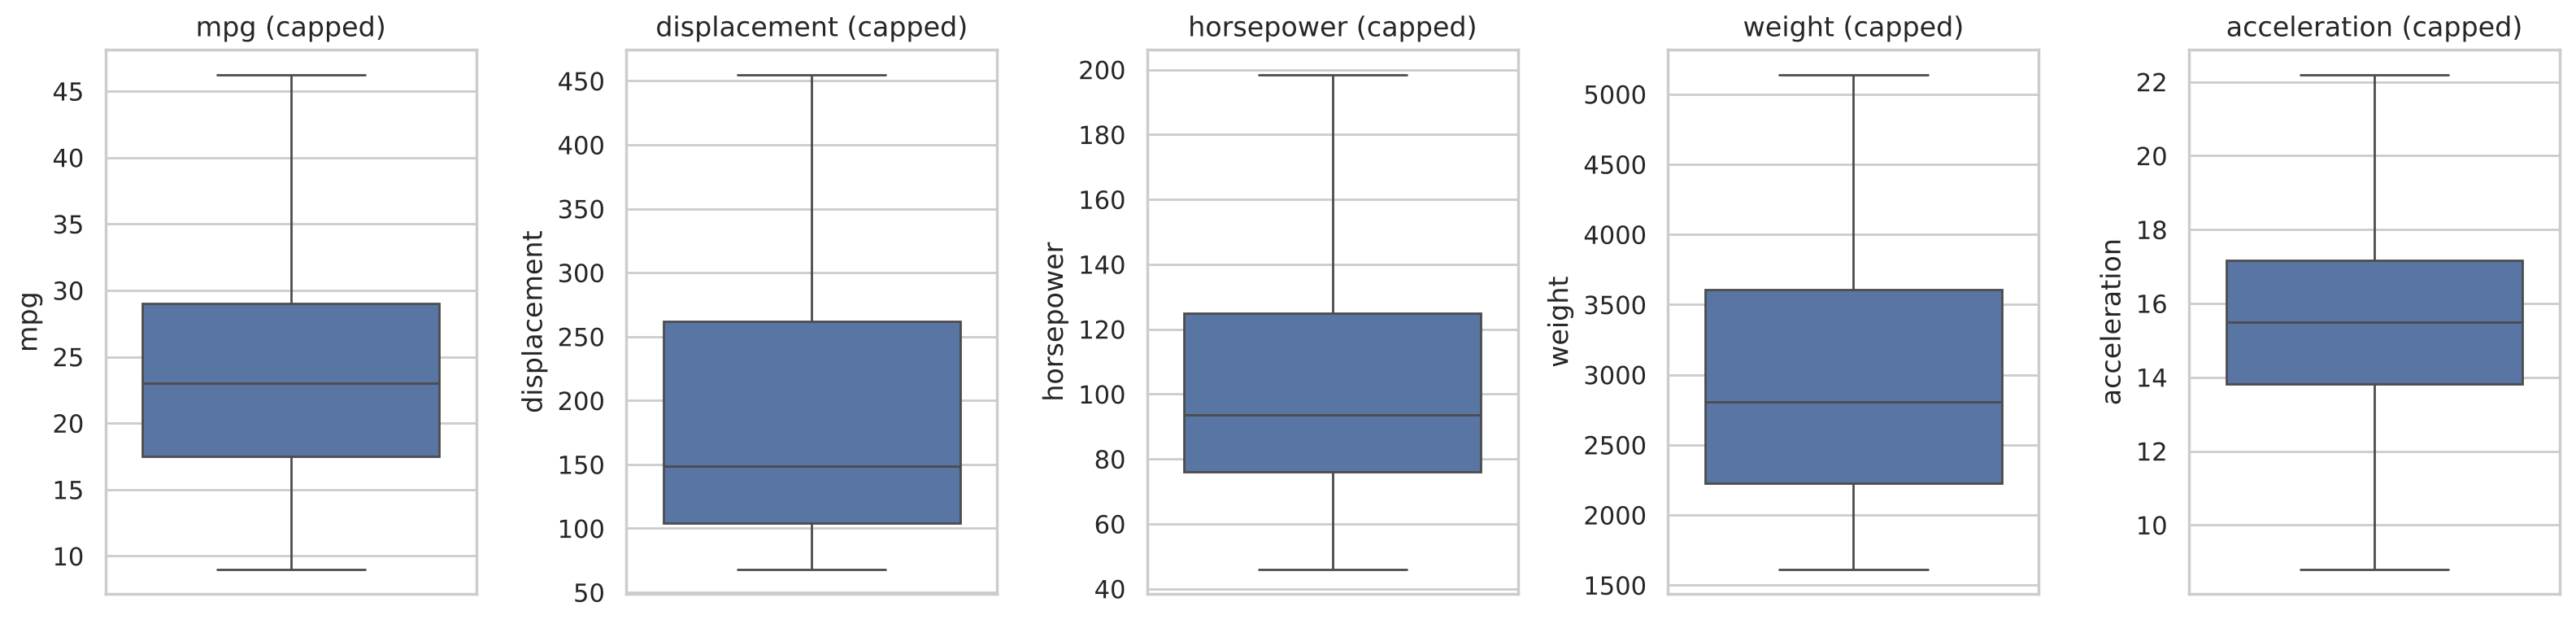

In [17]:
df_capped = df_clean.copy()
for col in num_cols:
    lower, upper = iqr_bounds(df_capped[col])
    df_capped[col] = df_capped[col].clip(lower, upper)

plt.figure(figsize=(16, 4))
for i, col in enumerate(num_cols, 1):
    plt.subplot(1, 5, i)
    sns.boxplot(y=df_capped[col])
    plt.title(col + " (capped)")
plt.tight_layout()
plt.show()

**Observation:** After capping, the boxplots have no dots outside the whiskers, and no rows were lost (still 398 rows). For example, the maximum `horsepower` changed from 230 to 198.5 and the maximum `mpg` from 46.6 to 46.25.

**My decision:** cap the outliers. The extreme `horsepower` values are powerful cars, which are valid and rare, not errors. Removing them (Option A) would delete 11 real cars and leave 387 rows, while capping keeps all 398 rows and reduces the effect of the extreme values.

---
# Task 4: Normalize numerical features (Min-Max and Z-score)
The columns have very different scales (`weight` is in the thousands, `acceleration` around 15). Distance-based and gradient-based models are affected by this.

We use the capped data (`df_capped`); you can change it to the dataframe you chose in Task 3.

In [18]:
scale_cols = ["mpg", "displacement", "horsepower", "weight", "acceleration"]
df_capped[scale_cols].describe().loc[["mean", "std", "min", "max"]].round(2)

,mpg,displacement,horsepower,weight,acceleration
mean,23.51,193.43,103.79,2970.42,15.55
std,7.81,104.27,36.77,846.84,2.69
min,9.00,68.00,46.00,1613.00,8.80
max,46.25,455.00,198.50,5140.00,22.20


### 4.1 Min-Max normalization
Rescales each feature to the range 0 to 1: `x' = (x - min) / (max - min)`.

In [19]:
from sklearn.preprocessing import MinMaxScaler

minmax = MinMaxScaler()
df_minmax = df_capped.copy()
df_minmax[scale_cols] = minmax.fit_transform(df_capped[scale_cols])

df_minmax[scale_cols].describe().loc[["mean", "std", "min", "max"]].round(2)

,mpg,displacement,horsepower,weight,acceleration
mean,0.39,0.32,0.38,0.38,0.5
std,0.21,0.27,0.24,0.24,0.2
min,0.00,0.00,0.00,0.00,0.0
max,1.00,1.00,1.00,1.00,1.0


**Observation:** After Min-Max scaling every feature has a minimum of 0 and a maximum of 1, so all five features are on the same scale. For example, `weight` now has a mean of 0.38 instead of about 2970.

### 4.2 Z-score standardization
Mean 0 and standard deviation 1: `z = (x - mean) / std`.

In [20]:
from sklearn.preprocessing import StandardScaler

standard = StandardScaler()
df_standard = df_capped.copy()
df_standard[scale_cols] = standard.fit_transform(df_capped[scale_cols])

df_standard[scale_cols].describe().loc[["mean", "std", "min", "max"]].round(2)

,mpg,displacement,horsepower,weight,acceleration
mean,-0.00,-0.00,0.00,-0.00,-0.00
std,1.00,1.00,1.00,1.00,1.00
min,-1.86,-1.20,-1.57,-1.60,-2.51
max,2.91,2.51,2.58,2.57,2.47


**Observation:** After Z-score standardization every feature has a mean of 0 and a standard deviation of 1. The values are now both negative and positive; for example `acceleration` goes from -2.51 to 2.47.

---
# Task 5: PCA (only if the features are correlated)
PCA is useful when features are strongly correlated, because they contain overlapping information. So we **check the correlation first**.

- close to **1** or **-1**: strong linear relationship
- close to **0**: weak or no linear relationship

### 5.1 Correlation check

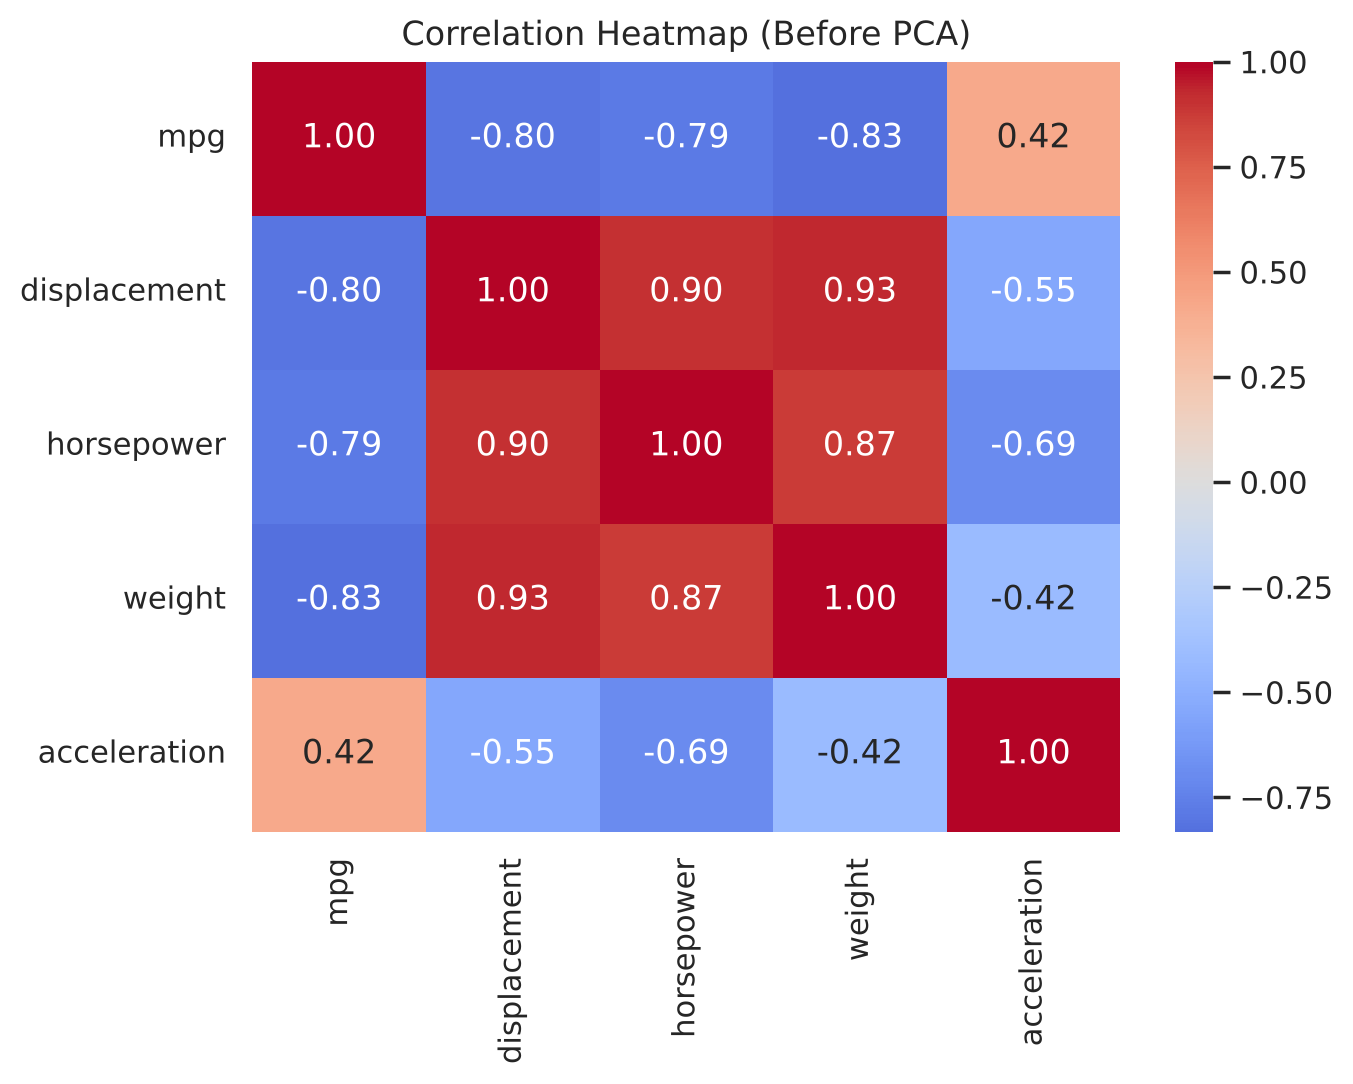

In [21]:
corr = df_standard[scale_cols].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap (Before PCA)")
plt.show()

**Observation:** Many features are strongly correlated: `displacement`, `horsepower` and `weight` are strongly positive with each other (0.87 to 0.93), and `mpg` is strongly negative with all three (-0.79 to -0.83). `acceleration` has weaker correlations. This means several features carry overlapping information, so PCA makes sense.

In [22]:
# List the strongly correlated pairs (absolute correlation above 0.7)
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
             .stack()
             .rename("correlation")
             .reset_index())
strong = pairs[pairs["correlation"].abs() > 0.7]
strong

,level_0,level_1,correlation
1,mpg,displacement,-0.804353
2,mpg,horsepower,-0.785846
3,mpg,weight,-0.831901
7,displacement,horsepower,0.899862
8,displacement,weight,0.932824
13,horsepower,weight,0.874050


### 5.2 Apply PCA only if the correlation is strong
The cell below applies PCA only when there is at least one strongly correlated pair.

In [23]:
from sklearn.decomposition import PCA

if len(strong) > 0:
    pca = PCA(n_components=len(scale_cols))
    components = pca.fit_transform(df_standard[scale_cols])

    print("Explained variance ratio:", pca.explained_variance_ratio_.round(3))
    print("Cumulative:              ", pca.explained_variance_ratio_.cumsum().round(3))
else:
    print("No strong correlation found, so PCA is not needed.")

Explained variance ratio: [0.788 0.142 0.045 0.016 0.01 ]
Cumulative:               [0.788 0.93  0.974 0.99  1.   ]


**Observation:** PCA ran because there are 6 strongly correlated pairs. The first component explains 78.8% of the variance, the first two together 93.0%, and the first three 97.4%. So the 5 features can be described by 2 or 3 components with little information lost.

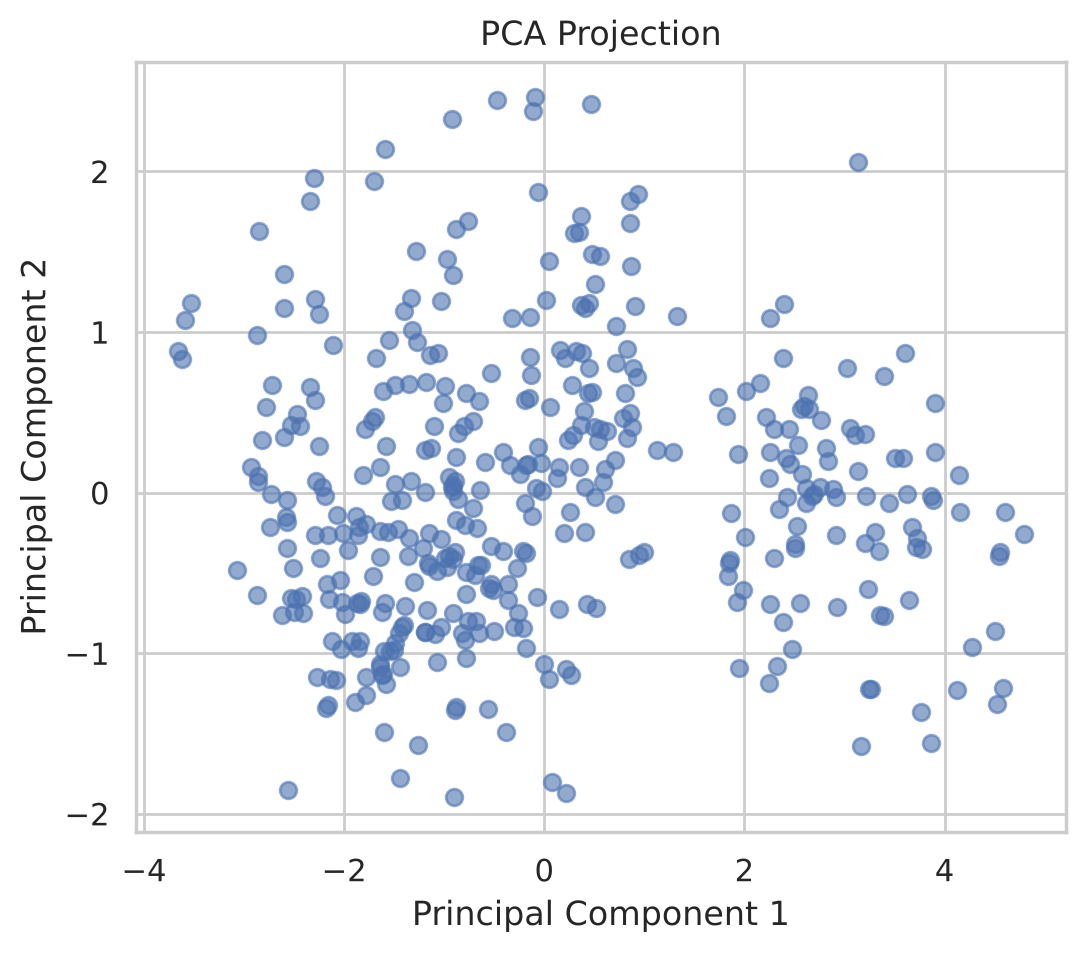

In [24]:
if len(strong) > 0:
    plt.figure(figsize=(6, 5))
    plt.scatter(components[:, 0], components[:, 1], alpha=0.6)
    plt.title("PCA Projection")
    plt.xlabel("Principal Component 1")
    plt.ylabel("Principal Component 2")
    plt.show()

**Observation:** The cars are spread mostly along the first principal component (the horizontal axis), which fits the fact that it explains 78.8% of the variance. The second component adds a smaller spread.

**My decision:** keep 3 principal components. Two components explain 93.0% of the variance and three explain 97.4%, which passes the 95% target. If we only need a 2D plot, 2 components are enough.

---
## Summary
The Auto MPG data was mostly clean: there are no duplicate rows and only one column has missing values. We found 6 missing `horsepower` values (written as `?`), inconsistent brand names in `car_name`, and `origin` stored as a number instead of a category. We filled the missing values with the median, capped the outliers with the IQR limits (instead of removing real cars), scaled the features with Min-Max and Z-score, and used PCA because several features were strongly correlated. We learned that every step needs a decision with a reason: for example the median is safer than the mean when the data is skewed, and an outlier can be a valid rare case.